# Case Study A — EDA with initial-phase outlier investigation

### Follow-up to `case_study_A_eda.ipynb`

In the first EDA notebook, the within-cycle waveform comparison (Pneumatic pressure / Velocity /
Acceleration piston rod, early vs. mid-life vs. near-failure cycle) showed sharp positive/negative
spikes at the start of the plotted window, settling down afterwards. This notebook investigates:

1. **What exactly is spiking?** The earlier plot's x-axis is the *within-cycle sample index*
   (0–99), not the device's life stage — so "settles down after the initial phase" could mean
   either (a) a transient at the start of *every* cycle's recording, or (b) a genuine
   *early-in-life* ("running-in") effect across the device's 4,766-cycle lifetime. Part 1
   disambiguates the two.
2. **Are there genuine early-life outliers?** Part 2 builds a data-driven detector that flags
   early cycles whose value differs significantly from the later, steady-state ("a regime")
   value, per channel.
3. **Does it matter for the EDA conclusions?** Part 3 repeats the key analyses from the first
   notebook — distributions, degradation-trend correlations, channel correlation matrix —
   excluding the flagged initial-phase outlier cycles, and compares before/after.

Same prerequisites as the first notebook (`zema_env` kernel, `pandas`/`seaborn`, cached dataset).


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd()))
from case_study_A_analysis import Config, load_zema  # reuse the pipeline's own loader

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 4)

cfg = Config()
X, UX, y = load_zema(cfg)

CHANNEL_NAMES = [
    "Acceleration plain bearing", "Acceleration piston rod", "Acceleration ball bearing",
    "Active current", "Axial force",
    "Motor current phase 1", "Motor current phase 2", "Motor current phase 3",
    "Pneumatic pressure", "Sound pressure", "Velocity",
]
D = cfg.datapoints_per_cycle
N = X.shape[0]


def channel_block(name):
    i = CHANNEL_NAMES.index(name)
    return X[:, i * D:(i + 1) * D]


print(f"X {X.shape}  |  {N} cycles  |  {D} within-cycle samples/channel")


X (4766, 1100)  |  4766 cycles  |  100 within-cycle samples/channel


/Users/emanuelebuchicchio/repos/case_study_a/zema_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part 1 — What is actually spiking?

Re-examine the original comparison, but overlay several example cycles spread across the *whole*
life (not just 3), zoomed on the first samples of each cycle. If the spike shape/magnitude is the
same regardless of which life-stage the cycle comes from, it is a **within-cycle acquisition
transient**, not an early-life effect.


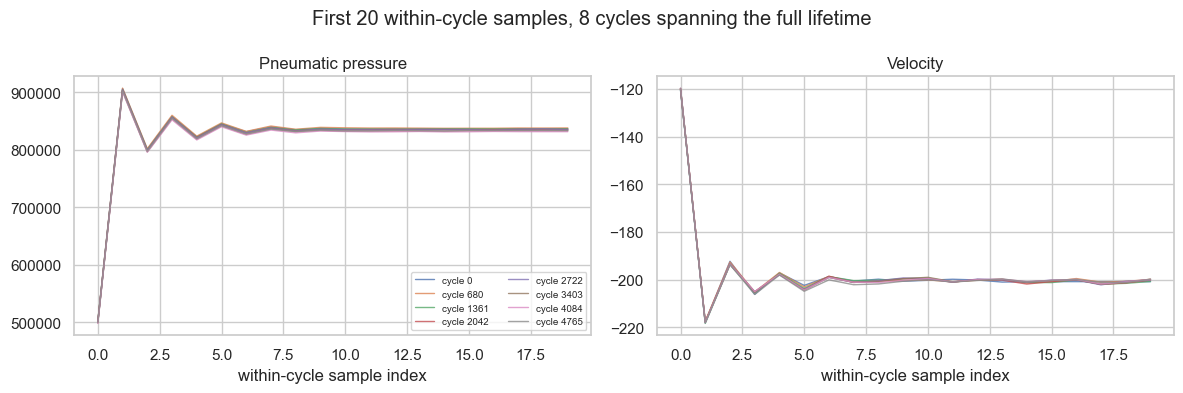

In [2]:
example_idx = np.linspace(0, N - 1, 8, dtype=int)
plot_channels = ["Pneumatic pressure", "Velocity"]

fig, axes = plt.subplots(1, len(plot_channels), figsize=(12, 4))
for ax, name in zip(axes, plot_channels):
    block = channel_block(name)
    for k in example_idx:
        ax.plot(block[k, :20], lw=1, alpha=0.8, label=f"cycle {k}")
    ax.set_title(name)
    ax.set_xlabel("within-cycle sample index")
axes[0].legend(fontsize=7, ncol=2)
fig.suptitle("First 20 within-cycle samples, 8 cycles spanning the full lifetime")
plt.tight_layout()
plt.show()


Every example cycle — early, mid-life, and near-failure alike — shows the same spike at the very
start of its recording, then settles to the same steady band. This is a transient at the start of
*each cycle's own 100-sample window*, not something tied to the device's degradation stage.

Quantify it: for every channel, compute each sample position's average absolute deviation from
that cycle's own median, averaged over **all 4,766 cycles** (so early/mid/late life all contribute
equally). A position-dependent spike that survives this averaging confirms a systematic, life-stage
-independent transient. The settling length `K` is the number of leading positions whose average
deviation exceeds 5× the steady-state baseline level (median of positions 20+).


In [3]:
BASELINE_FROM = 20
SPIKE_RATIO = 5.0

settle_K, pos_dev = {}, {}
for name in CHANNEL_NAMES:
    block = channel_block(name)
    dev = np.abs(block - np.median(block, axis=1, keepdims=True))
    pos_mean_dev = dev.mean(axis=0)
    baseline = np.median(pos_mean_dev[BASELINE_FROM:])
    K = 0
    for p in range(len(pos_mean_dev)):
        if pos_mean_dev[p] > SPIKE_RATIO * baseline:
            K = p + 1
        else:
            break
    settle_K[name] = K
    pos_dev[name] = pos_mean_dev

settle_df = pd.DataFrame({
    "settling length K": settle_K,
    "peak deviation (pos 0)": {n: pos_dev[n][0] for n in CHANNEL_NAMES},
    "steady baseline": {n: np.median(pos_dev[n][BASELINE_FROM:]) for n in CHANNEL_NAMES},
})
settle_df["peak / baseline"] = settle_df["peak deviation (pos 0)"] / settle_df["steady baseline"]
settle_df.sort_values("settling length K", ascending=False)


,settling length K,peak deviation (pos 0),steady baseline,peak / baseline
Pneumatic pressure,7,336042.5765,1137.0793,295.5313
Velocity,6,80.5350,0.5479,146.9947
Axial force,3,2.1724,0.0444,48.9423
Active current,1,1.0744,0.2123,5.0609
Acceleration plain bearing,0,1.3502,1.0974,1.2304
Acceleration piston rod,0,2.7609,4.0021,0.6899
Acceleration ball bearing,0,2.6699,3.1381,0.8508
Motor current phase 1,0,0.7756,2.8360,0.2735
Motor current phase 2,0,1.4924,2.8246,0.5284
Motor current phase 3,0,2.2501,2.6943,0.8351


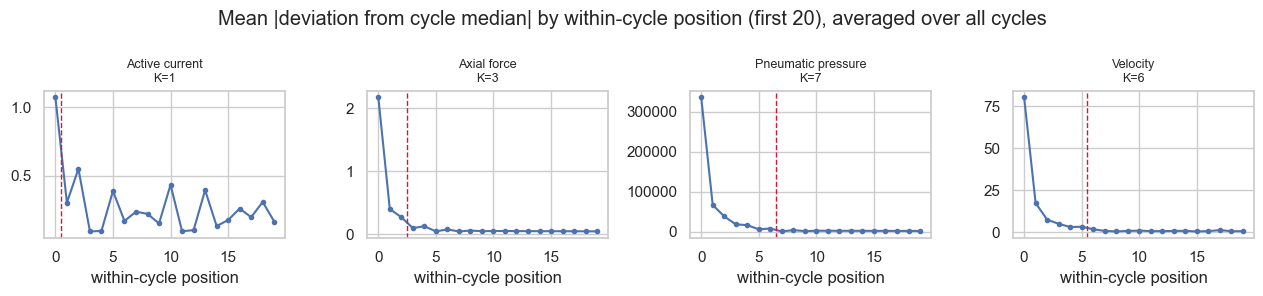

In [4]:
transient_channels = [n for n, k in settle_K.items() if k > 0]
fig, axes = plt.subplots(1, len(transient_channels), figsize=(3.2 * len(transient_channels), 3))
if len(transient_channels) == 1:
    axes = [axes]
for ax, name in zip(axes, transient_channels):
    ax.plot(pos_dev[name][:20], marker="o", ms=3)
    ax.axvline(settle_K[name] - 0.5, color="crimson", ls="--", lw=1)
    ax.set_title(f"{name}\nK={settle_K[name]}", fontsize=9)
    ax.set_xlabel("within-cycle position")
fig.suptitle("Mean |deviation from cycle median| by within-cycle position (first 20), averaged over all cycles")
plt.tight_layout()
plt.show()


**Part 1 conclusion.** Pneumatic pressure (K≈7), Velocity (K≈6) and Axial force (K≈3) have a
short, systematic settling transient at the start of *every* cycle's recording — present with the
same magnitude whether the cycle is from early, mid, or near-failure life. This is far more
consistent with a **measurement/acquisition artifact** (sensor or DAQ settling time right after
each cycle trigger) than with any physical life-stage effect, and it answers the original
question directly for pressure and velocity: yes, that spike looks like a measurement-system
issue, not a degradation signal.

One practical consequence: `case_study_A_analysis.py`'s `load_zema()` takes the **first**
`datapoints_per_cycle` (100 of 2,000) raw samples per cycle (see `ZeMASamples._extract_data`), so
for Pneumatic pressure this transient occupies ~7% of the raw features the model actually trains
on for that channel.


## Part 2 — Genuine early-in-life ("running-in") outliers

Having isolated the within-cycle artifact, check for a *different* phenomenon: cycles in the first
part of the device's life whose value is genuinely out of line with the later, steady-state
("a regime") value — e.g. mechanical run-in/break-in. Method, per channel:

1. Use the **clean** per-cycle mean — the within-cycle mean computed *after* dropping that
   channel's own settling window `K` from Part 1, so the acquisition transient can't masquerade as
   an early-life effect.
2. Build a robust steady-state reference (median/MAD) from a mid-life window (cycles 1000–3000),
   away from both the start and the near-failure end.
3. Flag a cycle in the early window (first 500 cycles) as an outlier if its clean mean's robust
   z-score exceeds 3 in absolute value.


In [5]:
REF_LO, REF_HI = 1000, 3000
EARLY_N = 500
Z_THRESH = 3.0


def clean_mean(name):
    block = channel_block(name)
    K = settle_K[name]
    return block[:, K:].mean(axis=1) if K > 0 else block.mean(axis=1)


raw_flag_counts, clean_flag_counts, masks = {}, {}, {}
for name in CHANNEL_NAMES:
    raw_m = channel_block(name).mean(axis=1)
    cln_m = clean_mean(name)
    for m, store in [(raw_m, raw_flag_counts), (cln_m, clean_flag_counts)]:
        ref = m[REF_LO:REF_HI]
        med = np.median(ref)
        mad = np.median(np.abs(ref - med)) * 1.4826 + 1e-15
        z_early = (m[:EARLY_N] - med) / mad
        store[name] = int((np.abs(z_early) > Z_THRESH).sum())
    ref = cln_m[REF_LO:REF_HI]
    med, mad = np.median(ref), np.median(np.abs(ref - np.median(ref))) * 1.4826 + 1e-15
    flagged = np.zeros(N, dtype=bool)
    flagged[:EARLY_N] = np.abs((cln_m[:EARLY_N] - med) / mad) > Z_THRESH
    masks[name] = flagged

outlier_df = pd.DataFrame({
    "settling K": settle_K,
    "n flagged (raw mean)": raw_flag_counts,
    "n flagged (clean mean)": clean_flag_counts,
})
outlier_df["frac flagged (clean, of first %d)" % EARLY_N] = outlier_df["n flagged (clean mean)"] / EARLY_N
outlier_df.sort_values("frac flagged (clean, of first %d)" % EARLY_N, ascending=False)


,settling K,n flagged (raw mean),n flagged (clean mean),"frac flagged (clean, of first 500)"
Axial force,3,374,375,0.750
Motor current phase 1,0,346,346,0.692
Motor current phase 2,0,64,64,0.128
Acceleration ball bearing,0,52,52,0.104
Velocity,6,172,44,0.088
Active current,1,31,27,0.054
Sound pressure,0,11,11,0.022
Acceleration plain bearing,0,9,9,0.018
Pneumatic pressure,7,1,1,0.002
Acceleration piston rod,0,0,0,0.000


For Pneumatic pressure, the clean-mean flag count stays at essentially zero — confirming Part 1:
once the acquisition transient is removed, pressure shows no real early-life effect. Velocity and
Active current drop sharply from the raw-mean count once the transient is removed, but keep a
smaller residual. Axial force and Motor current phase 1 stay large either way (their settling
window `K` is 0–3, too short to explain hundreds of flagged cycles) — a genuine, extended
early-life regime shift, consistent with mechanical run-in/break-in.

Channels are marked as having a genuine initial-phase effect if more than 5% of the early window
is flagged on the clean mean.


In [6]:
QUALIFY_FRAC = 0.05
qualifying = [
    n for n in CHANNEL_NAMES
    if outlier_df.loc[n, "n flagged (clean mean)"] / EARLY_N > QUALIFY_FRAC
]
print("Channels with a genuine initial-phase effect (>%.0f%% of first %d cycles flagged):"
      % (QUALIFY_FRAC * 100, EARLY_N))
for n in qualifying:
    print(f"  - {n}  ({outlier_df.loc[n, 'n flagged (clean mean)']}/{EARLY_N} cycles)")


Channels with a genuine initial-phase effect (>5% of first 500 cycles flagged):
  - Acceleration ball bearing  (52/500 cycles)
  - Active current  (27/500 cycles)
  - Axial force  (375/500 cycles)
  - Motor current phase 1  (346/500 cycles)
  - Motor current phase 2  (64/500 cycles)
  - Velocity  (44/500 cycles)


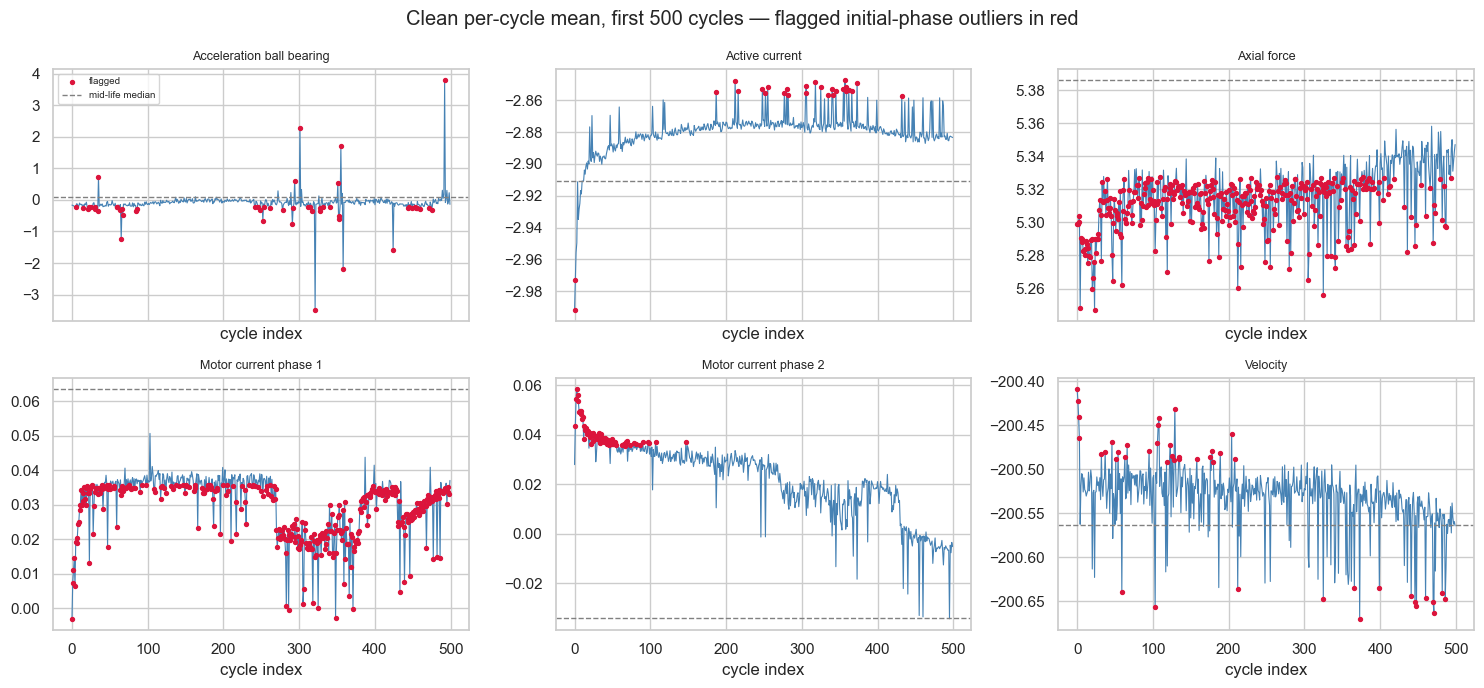

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, name in zip(axes.flat, qualifying):
    cln_m = clean_mean(name)
    flagged = masks[name]
    cyc = np.arange(EARLY_N)
    ax.plot(cyc, cln_m[:EARLY_N], lw=0.8, color="steelblue")
    ax.scatter(cyc[flagged[:EARLY_N]], cln_m[:EARLY_N][flagged[:EARLY_N]],
               color="crimson", s=8, zorder=3, label="flagged")
    ref = cln_m[REF_LO:REF_HI]
    ax.axhline(np.median(ref), color="gray", ls="--", lw=1, label="mid-life median")
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("cycle index")
for ax in axes.flat[len(qualifying):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=7)
fig.suptitle("Clean per-cycle mean, first %d cycles — flagged initial-phase outliers in red" % EARLY_N)
plt.tight_layout()
plt.show()


## Part 3 — Repeating the EDA excluding initial-phase outliers

Build one combined outlier-cycle set from the qualifying channels (majority vote: flagged by at
least 2 of them, to avoid one noisy channel driving the exclusion on its own), then redo the
distribution, degradation-trend and correlation views from the first notebook with vs. without
those cycles.


In [8]:
VOTE_THRESH = 2
vote = np.sum([masks[n] for n in qualifying], axis=0)
is_outlier = vote >= VOTE_THRESH

print(f"Combined initial-phase outliers: {is_outlier.sum()} / {N} cycles "
      f"({is_outlier.sum() / N:.1%}), spanning cycle index "
      f"{np.where(is_outlier)[0].min()}-{np.where(is_outlier)[0].max()}")

df_mean_clean = pd.DataFrame({name: clean_mean(name) for name in CHANNEL_NAMES})
df_mean_clean["is_outlier"] = is_outlier
df_mean_clean["y"] = y


Combined initial-phase outliers: 286 / 4766 cycles (6.0%), spanning cycle index 0-493


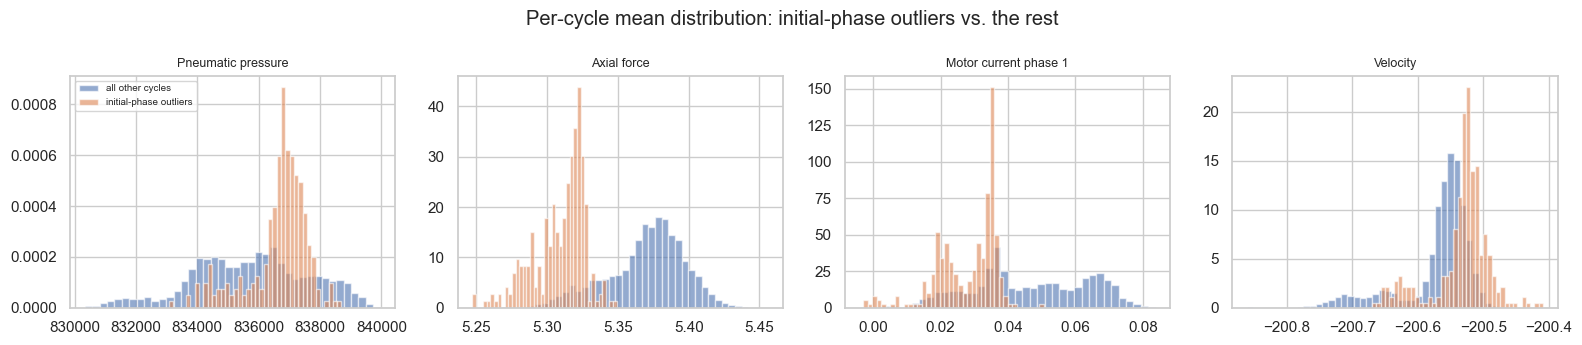

In [9]:
show_channels = ["Pneumatic pressure", "Axial force", "Motor current phase 1", "Velocity"]
fig, axes = plt.subplots(1, len(show_channels), figsize=(16, 3.5))
for ax, name in zip(axes, show_channels):
    ax.hist(df_mean_clean.loc[~is_outlier, name], bins=40, alpha=0.6, label="all other cycles", density=True)
    ax.hist(df_mean_clean.loc[is_outlier, name], bins=40, alpha=0.6, label="initial-phase outliers", density=True)
    ax.set_title(name, fontsize=9)
axes[0].legend(fontsize=7)
fig.suptitle("Per-cycle mean distribution: initial-phase outliers vs. the rest")
plt.tight_layout()
plt.show()


In [10]:
corr_all = df_mean_clean[CHANNEL_NAMES].corrwith(df_mean_clean["y"])
corr_excl = df_mean_clean.loc[~is_outlier, CHANNEL_NAMES].corrwith(df_mean_clean.loc[~is_outlier, "y"])
cmp = pd.DataFrame({"corr with y (all cycles)": corr_all, "corr with y (outliers excluded)": corr_excl})
cmp["|delta|"] = (cmp.iloc[:, 0] - cmp.iloc[:, 1]).abs()
cmp.sort_values("|delta|", ascending=False)


,corr with y (all cycles),corr with y (outliers excluded),|delta|
Axial force,0.1833,-0.0050,0.1883
Motor current phase 1,-0.1801,-0.3160,0.1358
Active current,0.1167,0.2099,0.0932
Sound pressure,-0.3014,-0.2227,0.0787
Velocity,-0.0990,-0.0388,0.0601
Acceleration ball bearing,0.5407,0.5980,0.0574
Motor current phase 2,-0.7387,-0.6862,0.0525
Acceleration piston rod,0.5152,0.4748,0.0404
Pneumatic pressure,-0.7289,-0.7566,0.0277
Motor current phase 3,0.7458,0.7644,0.0187


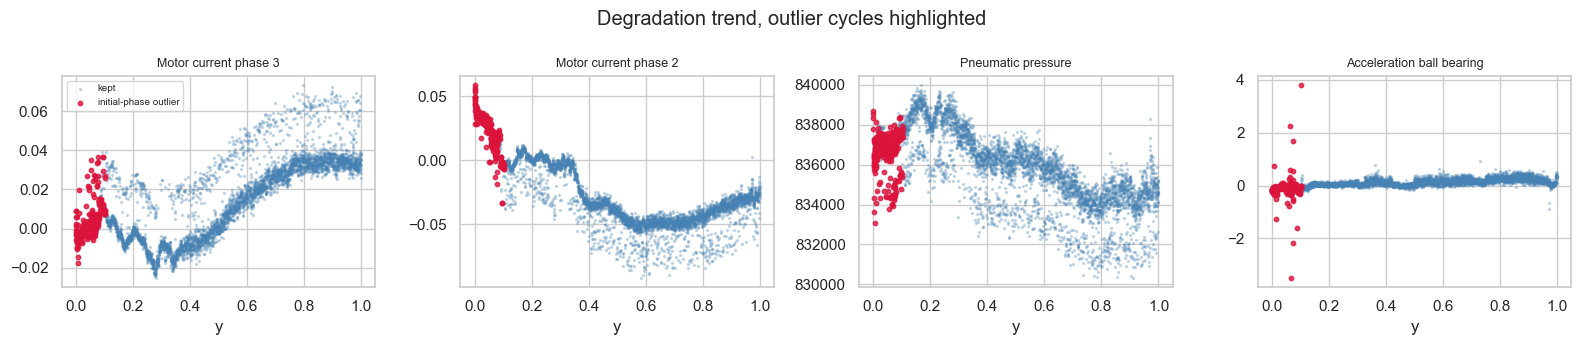

In [11]:
top = corr_all.abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, len(top), figsize=(16, 3.5))
for ax, name in zip(axes, top):
    ax.scatter(df_mean_clean.loc[~is_outlier, "y"], df_mean_clean.loc[~is_outlier, name],
               s=2, alpha=0.25, color="steelblue", label="kept")
    ax.scatter(df_mean_clean.loc[is_outlier, "y"], df_mean_clean.loc[is_outlier, name],
               s=10, alpha=0.8, color="crimson", label="initial-phase outlier")
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("y")
axes[0].legend(fontsize=7)
fig.suptitle("Degradation trend, outlier cycles highlighted")
plt.tight_layout()
plt.show()


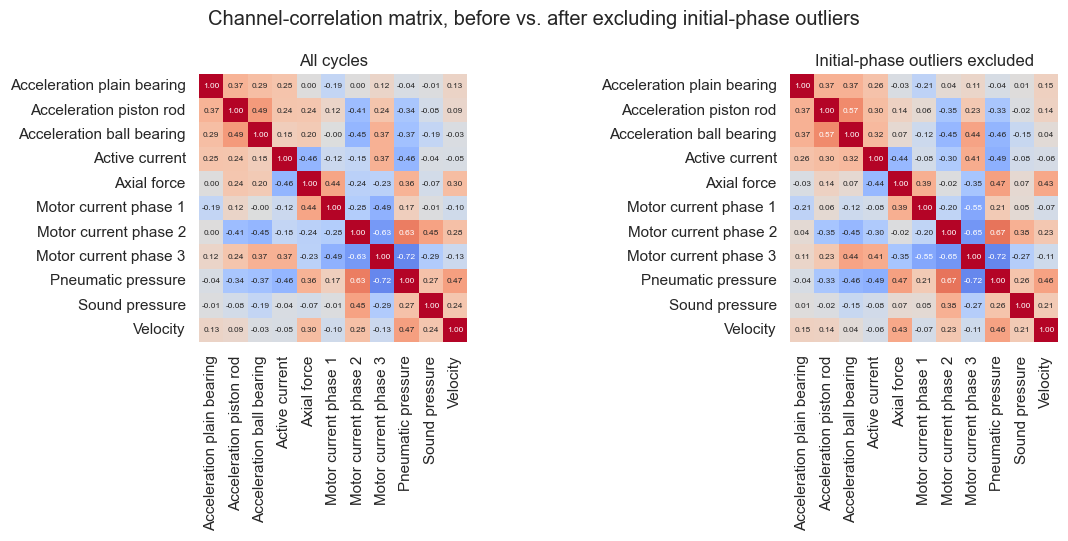

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
sns.heatmap(df_mean_clean[CHANNEL_NAMES].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, ax=axes[0], annot_kws={"fontsize": 6}, cbar=False)
axes[0].set_title("All cycles")
sns.heatmap(df_mean_clean.loc[~is_outlier, CHANNEL_NAMES].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, ax=axes[1], annot_kws={"fontsize": 6}, cbar=False)
axes[1].set_title("Initial-phase outliers excluded")
fig.suptitle("Channel-correlation matrix, before vs. after excluding initial-phase outliers")
plt.tight_layout()
plt.show()


## Summary

- **Pneumatic pressure / Velocity "spikes":** these are a **within-cycle acquisition transient**
  (the first ~6–7 of 100 samples in *every* cycle, at every life stage), not an early-device-life
  effect. It looks like a measurement/DAQ settling artifact rather than a degradation signal — for
  pressure specifically, once it's accounted for there is essentially no residual early-life
  deviation from the steady-state value.
- **Genuine initial-phase (running-in) outliers do exist**, but on different channels: Axial force
  and Motor current phase 1 show an extended early-life regime shift (most of the first few hundred
  cycles deviate strongly from the mid-life reference) consistent with mechanical run-in/break-in;
  Velocity, Motor current phase 2, Acceleration ball bearing and Active current show a smaller
  residual effect after the acquisition transient is removed.
- **Effect on the EDA conclusions:** excluding the combined initial-phase-outlier cycle set shifts
  the degradation-trend correlations by the amounts in the table in Part 3 (see `|delta|` column)
  — the ranking of which channels track consumed-lifetime fraction most strongly is essentially
  unchanged, but the magnitude of a few correlations moves measurably once the run-in cycles are
  excluded.
- **Actionable takeaway:** this is a data-quality finding upstream of `case_study_A_analysis.py`,
  not a change already reflected in `case_study_A_report.md`. Two independent, separately
  addressable issues: (1) trimming the first few within-cycle samples for pressure/velocity/axial
  force before feature extraction would remove a likely acquisition artifact from the model's raw
  inputs; (2) treating the first ~300–500 cycles as a distinct "run-in" regime (e.g., excluding
  them from training, or modeling them separately) would remove a genuine but non-representative
  mechanical transient from the degradation model, if confirmed against the original ZeMA
  documentation/metadata.
